# Portfolio of Evidence: CNN Image Classification with Goodbooks-10k
**Student:** Katlego Thejane (ST10104762) | **Module:** Programming for Data Analysis (PDAN8412w) | **Programme:** Postgraduate Diploma in Data Analytics, IIE Rosebank College

**Purpose.** Apache Spark prepares, profiles and labels the supplied `goodbooks-10k-books.csv` metadata (Stage A). TensorFlow/Keras then trains and evaluates a convolutional neural network (CNN) on the book-cover images that the metadata references (Stage B). The model predicts four balanced reader-popularity tiers derived only from `ratings_count`.

**Scope.** This is an image-classification proof of concept, not facial recognition. It demonstrates a transferable CNN workflow without the biometric consent and privacy obligations of a production face-recognition system.

**Integrity.** Run every cell before submission so that the notebook holds your own outputs. Do not report a metric that this run did not produce.

| Notebook section | Report section |
|---|---|
| 1-3 Environment, Spark loading, cleaning | 2-3 |
| 4-5 EDA and target construction | 4, 5.1 |
| 6 Feature selection (Spark MLlib) | 5.2 |
| 7-8 Spark hand-over and image download | 5.3 |
| 9-11 Split, pipeline, baseline CNN | 6.1 |
| 12 Evaluation metrics | 7 |
| 13-14 Retrained CNN and success criteria | 6.2, 8 |
| 15 Limitations | 9 |

## 1. Environment and reproducibility
Stage A needs Java (for PySpark). Stage B needs network access once, to retrieve the cover images named in the CSV. Place `goodbooks-10k-books.csv` beside this notebook (in Google Colab, upload it to the session first). The notebook was tested with Python 3.12, PySpark 4.3 (Java 21), TensorFlow 2.21 and Keras 3. Every figure is displayed and also saved to `poe_cnn_work/results/figures/` for the report.

In [ ]:
# Uncomment only if packages are missing (Colab already has most of them)
# %pip install -q pyspark tensorflow scikit-learn seaborn pillow requests pandas matplotlib

from pathlib import Path
import os, json, random, time, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# A fixed seed makes the sampling, the data split and the weight initialisation repeatable
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# File locations: all generated artefacts stay inside one working folder
DATA_PATH = Path("goodbooks-10k-books.csv")
WORK_DIR = Path("poe_cnn_work")
IMAGE_DIR = WORK_DIR / "images"
RESULTS_DIR = WORK_DIR / "results"
FIG_DIR = RESULTS_DIR / "figures"
for folder in (WORK_DIR, IMAGE_DIR, RESULTS_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.exists():
    raise FileNotFoundError(f"{DATA_PATH} not found. Place it in {Path.cwd()} (Colab: upload it to the session).")

# Shared plot style so that every report figure looks consistent
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 180, "font.size": 10, "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.8, "axes.axisbelow": True})
FIGSIZE = (6.6, 3.84)
LABELS = ["Emerging", "Established", "Popular", "Blockbuster"]   # tier names, lowest to highest

def save_show(fig, filename):
    """Save a figure for the report, then display it in the notebook."""
    fig.savefig(FIG_DIR / filename, bbox_inches="tight", facecolor="white")
    plt.show()

RUN = {"seed": SEED, "python": platform.python_version()}      # facts collected for run_summary.json
print("Working directory:", WORK_DIR)

Working directory: poe_cnn_work


# Stage A: Spark metadata layer
## 2. Spark session and data loading
Spark DataFrames provide schema-aware loading, aggregation and duplicate removal (Zaharia *et al.*, 2016; Armbrust *et al.*, 2015; Apache Software Foundation, 2026). All metadata work (loading, cleaning, EDA, feature screening, labelling and sampling) stays in this stage. The session is stopped in Section 7 so that TensorFlow has the memory to itself.

In [ ]:
from pyspark.sql import SparkSession, functions as F, Window

spark = (SparkSession.builder
         .appName("POE_CNN_Goodbooks")
         .master("local[*]")                           # run Spark locally on all available cores
         .config("spark.sql.shuffle.partitions", "8")  # small data: few shuffle partitions
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.execution.arrow.pyspark.enabled", "false")   # plain toPandas() conversion for small data
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)
RUN["spark"] = spark.version

# Titles and authors contain quoted text with embedded commas and doubled quotation marks
# (for example book_id 6582 and 9265). Spark's default escape character is a backslash, which
# shifts the columns of those rows, so quote/escape are set to follow the RFC 4180 CSV convention.
books_raw = (spark.read.option("header", True).option("inferSchema", True)
             .option("multiLine", True).option("quote", '"').option("escape", '"')
             .csv(str(DATA_PATH)))
n_raw = books_raw.count()
print("Rows:", n_raw, "| Columns:", len(books_raw.columns))
books_raw.printSchema()

# Self-checks: numeric columns must be numeric and no row may be column-shifted
types = dict(books_raw.dtypes)
assert all(types[c] in ("int", "bigint", "double") for c in ["book_id", "ratings_count", "average_rating"]), \
    "Numeric columns were read as text - check the CSV quote/escape options."
assert books_raw.filter(~F.col("image_url").startswith("http")).count() == 0, "Column shift detected in CSV read."
print("Self-checks passed: schema and column alignment are correct.")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/16 12:32:20 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/11/16 12:32:20 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/16 12:32:21 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.3.0


Rows: 10000 | Columns: 23
root
 |-- book_id: integer (nullable = true)
 |-- goodreads_book_id: integer (nullable = true)
 |-- best_book_id: integer (nullable = true)
 |-- work_id: integer (nullable = true)
 |-- books_count: integer (nullable = true)
 |-- isbn: string (nullable = true)
 |-- isbn13: double (nullable = true)
 |-- authors: string (nullable = true)
 |-- original_publication_year: double (nullable = true)
 |-- original_title: string (nullable = true)
 |-- title: string (nullable = true)
 |-- language_code: string (nullable = true)
 |-- average_rating: double (nullable = true)
 |-- ratings_count: integer (nullable = true)
 |-- work_ratings_count: integer (nullable = true)
 |-- work_text_reviews_count: integer (nullable = true)
 |-- ratings_1: integer (nullable = true)
 |-- ratings_2: integer (nullable = true)
 |-- ratings_3: integer (nullable = true)
 |-- ratings_4: integer (nullable = true)
 |-- ratings_5: integer (nullable = true)
 |-- image_url: string (nullable = true)
 |

Self-checks passed: schema and column alignment are correct.


## 3. Data quality assessment and cleaning
The workflow checks missingness, duplicate identifiers, invalid ratings, non-positive popularity counts and absent image URLs. Rows without the minimum information needed for supervised image classification are removed. This is complete-case filtering of model-critical fields only; it makes no claim that missing values are random. Non-critical gaps (ISBN, language code, publication year) are reported but not imputed because they are not CNN inputs.

In [ ]:
# 3a. Missing values per column (only columns with gaps are shown)
missing = (books_raw.agg(*[F.sum(F.col(c).isNull().cast("int")).alias(c) for c in books_raw.columns])
           .toPandas().T.rename(columns={0: "missing_count"}))
missing["missing_pct"] = (missing["missing_count"] / n_raw * 100).round(2)
display(missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False))

# 3b. Duplicate identifiers
duplicate_ids = books_raw.groupBy("book_id").count().filter(F.col("count") > 1).count()
print("Duplicate book_id values:", duplicate_ids)

# 3c. Cleaning rules applied one at a time so that each rule's effect is auditable
critical = ["book_id", "title", "ratings_count", "average_rating", "image_url"]
s0 = books_raw
s1 = s0.dropDuplicates(["book_id"])                              # unique record key
s2 = s1.dropna(subset=critical)                                   # model-critical fields present
s3 = s2.filter(F.col("ratings_count") > 0)                        # positive engagement count
s4 = s3.filter(F.col("average_rating").between(1.0, 5.0))        # valid rating scale
books = s4.withColumn("original_publication_year", F.col("original_publication_year").cast("int")).cache()

audit = pd.DataFrame({"Cleaning rule": ["Raw records", "Remove duplicate book_id", "Drop missing critical fields",
                                         "Keep ratings_count > 0", "Keep average_rating in [1, 5]"],
                      "Rows remaining": [d.count() for d in (s0, s1, s2, s3, s4)]})
audit["Rows removed"] = audit["Rows remaining"].diff().abs().fillna(0).astype(int)
display(audit)
RUN["n_raw"], RUN["n_clean"] = int(n_raw), int(audit["Rows remaining"].iloc[-1])

,missing_count,missing_pct
language_code,1084,10.84
isbn,700,7.00
isbn13,585,5.85
original_title,585,5.85
original_publication_year,21,0.21


Duplicate book_id values: 0


,Cleaning rule,Rows remaining,Rows removed
0,Raw records,10000,0
1,Remove duplicate book_id,10000,0
2,Drop missing critical fields,10000,0
3,Keep ratings_count > 0,10000,0
4,"Keep average_rating in [1, 5]",10000,0


## 4. Exploratory data analysis
`ratings_count` is a Goodreads engagement proxy, not verified sales or bestseller status. The summary statistics and the three figures below are the basis for the report's EDA section.

In [ ]:
# 4a. Descriptive statistics from Spark (the median is computed exactly, not approximately)
desc_cols = ["average_rating", "ratings_count", "work_text_reviews_count", "books_count", "original_publication_year"]
stats = (books.select(*desc_cols).summary("count", "mean", "stddev", "min", "max")
         .toPandas().set_index("summary").astype(float).T)
stats.insert(4, "median", [books.agg(F.expr(f"percentile({c}, 0.5)")).first()[0] for c in desc_cols])
display(stats.round(2))

# 4b. Skewness before and after a log10 transformation (used for visualisation only)
skew = books.agg(F.skewness("ratings_count").alias("raw"),
                 F.skewness(F.log10("ratings_count")).alias("log10")).first()
print(f"Skewness of ratings_count: raw = {skew['raw']:.2f}, log10 = {skew['log10']:.2f}")

# 4c. Bring the small columns needed for plotting into pandas
eda_pdf = books.select("average_rating", "ratings_count", "language_code").toPandas()
english = eda_pdf["language_code"].isin(["eng", "en-US", "en-GB", "en-CA"]).mean() * 100
unknown = eda_pdf["language_code"].isna().mean() * 100
print(f"English-coded records: {english:.1f}% | missing language code: {unknown:.1f}%")

summary,count,mean,stddev,min,median,max
average_rating,10000.0,4.00,0.25,2.47,4.02,4.82
ratings_count,10000.0,54001.24,157369.96,2716.00,21155.50,4780653.00
work_text_reviews_count,10000.0,2919.96,6124.38,3.00,1402.00,155254.00
books_count,10000.0,75.71,170.47,1.00,40.00,3455.00
original_publication_year,9979.0,1981.99,152.58,-1750.00,2004.00,2017.00


Skewness of ratings_count: raw = 13.06, log10 = 1.38


English-coded records: 87.3% | missing language code: 10.8%


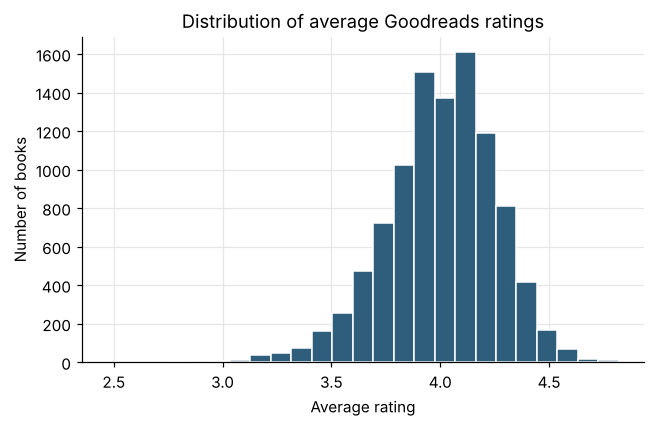

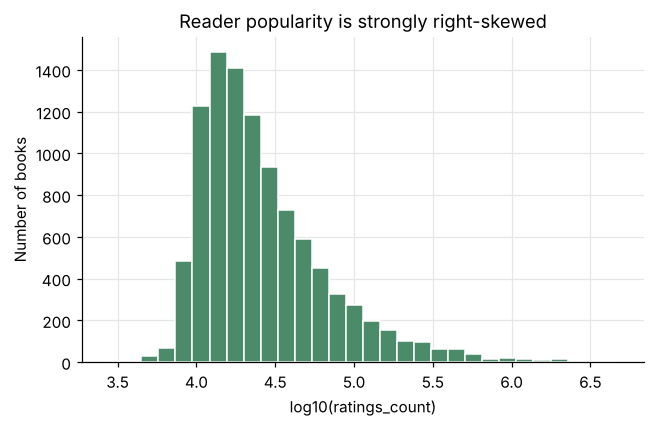

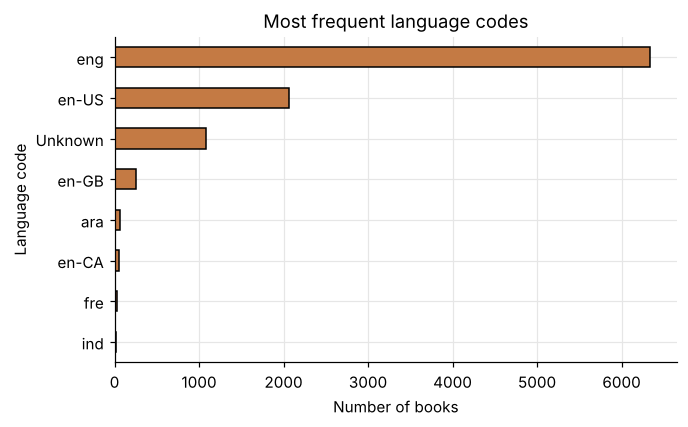

In [ ]:
# Figure 1: distribution of average ratings
fig, ax = plt.subplots(figsize=FIGSIZE)
sns.histplot(eda_pdf["average_rating"], bins=25, color="#2F5D7C", edgecolor="white", alpha=1, ax=ax)
ax.set(title="Distribution of average Goodreads ratings", xlabel="Average rating", ylabel="Number of books")
save_show(fig, "fig1_average_rating.png")

# Figure 2: popularity is heavily right-skewed, so it is plotted on a log10 scale
fig, ax = plt.subplots(figsize=FIGSIZE)
sns.histplot(np.log10(eda_pdf["ratings_count"]), bins=30, color="#4B8B6A", edgecolor="white", alpha=1, ax=ax)
ax.set(title="Reader popularity is strongly right-skewed", xlabel="log10(ratings_count)", ylabel="Number of books")
save_show(fig, "fig2_log_ratings_count.png")

# Figure 3: most frequent language codes (missing codes are shown as 'Unknown')
fig, ax = plt.subplots(figsize=FIGSIZE)
(eda_pdf["language_code"].fillna("Unknown").value_counts().head(8).sort_values()
 .plot.barh(ax=ax, color="#C47A44", edgecolor="black"))
ax.set(title="Most frequent language codes", xlabel="Number of books", ylabel="Language code")
save_show(fig, "fig3_language_codes.png")

## 5. Target construction
Four classes are created with Spark `ntile(4)` after ordering by `ratings_count` (ties broken by `book_id`). This yields near-equal classes, which keeps the task genuinely multi-class and makes macro-averaged metrics interpretable. An `is_placeholder` flag marks Goodreads "no photo" covers (see Section 7).

In [ ]:
# NTILE needs a global ordering, so the window has no partition; this is acceptable for 10,000 rows
w = Window.orderBy(F.col("ratings_count"), F.col("book_id"))
label_map = F.create_map([F.lit(x) for x in [1, "Emerging", 2, "Established", 3, "Popular", 4, "Blockbuster"]])
books_labeled = (books.withColumn("quartile", F.ntile(4).over(w))
                 .withColumn("label_name", label_map[F.col("quartile")])
                 .withColumn("label", F.col("quartile") - 1)                              # 0..3 for Keras
                 .withColumn("is_placeholder", F.col("image_url").contains("nophoto"))   # Goodreads "no photo" image
                 .cache())

tiers = (books_labeled.groupBy("label", "label_name")
         .agg(F.count("*").alias("n"), F.min("ratings_count").alias("min"),
              F.expr("percentile(ratings_count, 0.5)").alias("median"),     # exact median
              F.max("ratings_count").alias("max"),
              F.sum(F.col("is_placeholder").cast("int")).alias("placeholder_covers"))
         .orderBy("label").toPandas())
tiers["placeholder_pct"] = (tiers["placeholder_covers"] / tiers["n"] * 100).round(1)
tiers["genuine_covers"] = tiers["n"] - tiers["placeholder_covers"]
display(tiers)
RUN["placeholder_total"] = int(tiers["placeholder_covers"].sum())
RUN["genuine_covers_per_tier"] = tiers["genuine_covers"].astype(int).tolist()
print(f"Placeholder covers: {RUN['placeholder_total']} of {RUN['n_clean']} "
      f"({RUN['placeholder_total'] / RUN['n_clean'] * 100:.1f}%)")

,label,label_name,n,min,median,max,placeholder_covers,placeholder_pct,genuine_covers
0,0,Emerging,2500,2716,10960.5,13568,965,38.6,1535
1,1,Established,2500,13569,16775.0,21154,899,36.0,1601
2,2,Popular,2500,21157,27854.5,41052,847,33.9,1653
3,3,Blockbuster,2500,41058,76322.5,4780653,621,24.8,1879


Placeholder covers: 3332 of 10000 (33.3%)


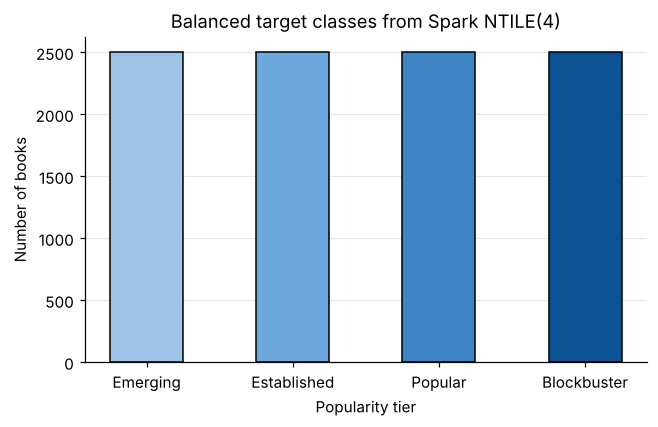

In [ ]:
# Figure 4: the target classes are balanced by construction
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.bar(tiers["label_name"], tiers["n"], color=["#9DC3E6", "#6EA8DC", "#3F85C5", "#0D5394"], edgecolor="black", width=0.5)
ax.set(title="Balanced target classes from Spark NTILE(4)", xlabel="Popularity tier", ylabel="Number of books")
ax.grid(axis="x", visible=False)
save_show(fig, "fig4_tier_balance.png")

## 6. Feature selection
A CNN learns its own visual features from pixels, so feature selection here means choosing which *inputs* are legitimate. Candidate numeric fields are screened with Spark MLlib (Meng *et al.*, 2016):
1. **Leakage check.** Spearman correlation with `ratings_count`. Fields that are components of, or closely track, the target's own rating count would leak it (Kaufman *et al.*, 2012).
2. **Univariate significance.** One-way ANOVA F-test of each field across the four tiers, with p-values and eta-squared (share of variance explained by tier). PySpark has no built-in ANOVA test, so the F statistic is computed from Spark group counts, means and variances. Count-type fields are log10-transformed first because they are heavily right-skewed (Spearman correlation is rank-based and unaffected).

The decision rule is stated in advance: leakage fields are excluded; the remaining metadata are reported for context but not used, because the module task is image recognition. The CNN input is therefore the cover image only.

In [ ]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation
from scipy import stats as sps

leak_cols = ["work_ratings_count", "ratings_1", "ratings_2", "ratings_3", "ratings_4", "ratings_5", "work_text_reviews_count"]
meta_cols = ["average_rating", "books_count", "original_publication_year"]
candidates = leak_cols + meta_cols
count_like = leak_cols + ["books_count"]                          # skewed counts -> log10(x + 1)

# Screening table: label, target field, and every candidate (counts log-transformed); 21 missing years dropped for this test only
screen = books_labeled.select(
    F.col("label").cast("double").alias("label"), "ratings_count",
    *[(F.log10(F.col(c) + 1) if c in count_like else F.col(c)).alias(c) for c in candidates]).dropna().cache()
n_screen = screen.count()

# (1) Spearman rank correlation of every candidate with ratings_count (first row of the matrix)
vec = VectorAssembler(inputCols=["ratings_count"] + candidates, outputCol="features").transform(screen)
corr = Correlation.corr(vec, "features", "spearman").head()[0].toArray()[0, 1:]

# (2) One-way ANOVA from Spark group statistics: n, mean and sample variance of each feature in each tier
aggs = [F.count("*").alias("n")]
for c in candidates:
    aggs += [F.mean(c).alias(f"{c}__mean"), F.var_samp(c).alias(f"{c}__var")]
grp = screen.groupBy("label").agg(*aggs).toPandas().sort_values("label")
n_g = grp["n"].to_numpy(float)
N, k = n_g.sum(), len(n_g)
df1, df2 = k - 1, N - k                                           # df between = 3, df within = N - 4
rows = []
for c in candidates:
    m_g, v_g = grp[f"{c}__mean"].to_numpy(), grp[f"{c}__var"].to_numpy()
    grand = (n_g * m_g).sum() / N
    ss_between = (n_g * (m_g - grand) ** 2).sum()                 # variation of tier means around the grand mean
    ss_within = ((n_g - 1) * v_g).sum()                           # variation of books around their own tier mean
    f_stat = (ss_between / df1) / (ss_within / df2)
    rows.append((f_stat, sps.f.sf(f_stat, df1, df2), ss_between / (ss_between + ss_within)))
anova = pd.DataFrame(rows, columns=["F", "p_value", "eta_squared"])

screening = pd.DataFrame({"feature": candidates,
                          "group": ["Leakage risk"] * len(leak_cols) + ["Metadata"] * len(meta_cols),
                          "spearman_rho": corr.round(3)}).join(anova.round({"F": 1, "eta_squared": 3}))
screening["decision"] = np.where(screening["group"] == "Leakage risk",
                                 "Excluded: popularity count from the target's own rating process",
                                 "Excluded: not an image feature; context only")
display(screening.assign(p_value=screening["p_value"].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}")))
print(f"Rows used: {n_screen} | df between = {df1}, df within = {int(df2)}")
n_identity = books_labeled.filter(F.col("ratings_1") + F.col("ratings_2") + F.col("ratings_3")
                                  + F.col("ratings_4") + F.col("ratings_5") == F.col("work_ratings_count")).count()
print(f"Identity check: ratings_1..5 sum exactly to work_ratings_count for {n_identity} of {RUN['n_clean']} books.")
screening.to_csv(RESULTS_DIR / "feature_screening.csv", index=False)
RUN["feature_screening_rows"] = int(n_screen)

,feature,group,spearman_rho,F,p_value,eta_squared,decision
0,work_ratings_count,Leakage risk,0.982,11384.5,< 0.001,0.774,Excluded: popularity count from the target's o...
1,ratings_1,Leakage risk,0.701,3249.5,< 0.001,0.494,Excluded: popularity count from the target's o...
2,ratings_2,Leakage risk,0.759,4168.6,< 0.001,0.556,Excluded: popularity count from the target's o...
3,ratings_3,Leakage risk,0.873,6838.4,< 0.001,0.673,Excluded: popularity count from the target's o...
4,ratings_4,Leakage risk,0.940,9463.7,< 0.001,0.740,Excluded: popularity count from the target's o...
5,ratings_5,Leakage risk,0.905,7762.4,< 0.001,0.700,Excluded: popularity count from the target's o...
6,work_text_reviews_count,Leakage risk,0.614,1917.3,< 0.001,0.366,Excluded: popularity count from the target's o...
7,average_rating,Metadata,0.079,23.0,< 0.001,0.007,Excluded: not an image feature; context only
8,books_count,Metadata,0.394,554.2,< 0.001,0.143,Excluded: not an image feature; context only
9,original_publication_year,Metadata,-0.074,6.9,< 0.001,0.002,Excluded: not an image feature; context only


Rows used: 9979 | df between = 3, df within = 9975


Identity check: ratings_1..5 sum exactly to work_ratings_count for 10000 of 10000 books.


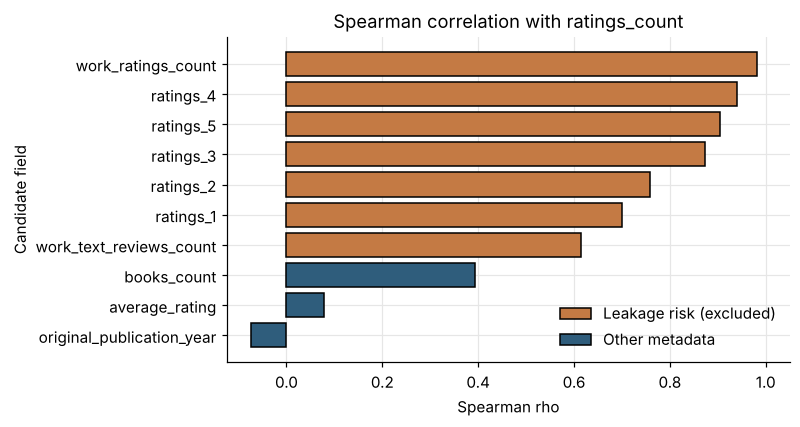

In [ ]:
# Figure 5: Spearman correlation of each candidate with ratings_count, coloured by decision group
from matplotlib.patches import Patch
order = screening.sort_values("spearman_rho")
fig, ax = plt.subplots(figsize=FIGSIZE)
colours = order["group"].map({"Leakage risk": "#C47A44", "Metadata": "#2F5D7C"})
ax.barh(order["feature"], order["spearman_rho"], color=colours, edgecolor="black")
ax.legend(handles=[Patch(facecolor="#C47A44", edgecolor="black", label="Leakage risk (excluded)"),
                   Patch(facecolor="#2F5D7C", edgecolor="black", label="Other metadata")], loc="lower right", frameon=False)
ax.set(title="Spearman correlation with ratings_count", xlabel="Spearman rho", ylabel="Candidate field")
ax.set_xlim(min(0, order["spearman_rho"].min() - 0.05), 1.05)
save_show(fig, "fig5_feature_screening.png")

## 7. Image sampling plan and Spark hand-over
For a manageable run, up to `MAX_PER_CLASS = 1200` books per tier are drawn at random (at most 4,800 images). A minimum of about 500 valid images per class is advisable for a scratch CNN; smaller counts should be reported as a limitation.

**Placeholder covers.** About one third of `image_url` values point to the same Goodreads "no photo" image, and its share varies by tier (Section 5). A CNN could learn that identical image as a shortcut that reflects missing metadata rather than cover design, so `EXCLUDE_PLACEHOLDER_COVERS = True` removes these books from the *image sample*. The tiers are still defined on all books, and every tier keeps more than 1,200 genuine covers, so each class is sampled at the same size.

The sampling manifest and the labelled table are written to disk, and the Spark session is stopped: Stage A ends here.

In [ ]:
MAX_PER_CLASS = 1200
EXCLUDE_PLACEHOLDER_COVERS = True        # set False to reproduce the unfiltered sample

pool = books_labeled.filter(~F.col("is_placeholder")) if EXCLUDE_PLACEHOLDER_COVERS else books_labeled
print("Placeholder covers excluded from the image sample:", books_labeled.count() - pool.count())

# Random order (seeded) then the first MAX_PER_CLASS rows of each tier
manifest_pd = (pool.select("book_id", "title", "image_url", "label", "label_name", "ratings_count", "is_placeholder")
               .orderBy(F.rand(SEED)).toPandas()
               .groupby("label", group_keys=False).head(MAX_PER_CLASS).reset_index(drop=True))
print(manifest_pd.groupby("label_name").size().reindex(LABELS))

# Persist Stage A outputs with pandas (avoids Hadoop file-system dependencies on Windows)
books_labeled.drop("image_url").toPandas().to_csv(WORK_DIR / "books_labeled.csv", index=False)
tiers.to_csv(RESULTS_DIR / "tier_summary.csv", index=False)
RUN["sampled_per_tier"] = {k: int(v) for k, v in manifest_pd.groupby("label_name").size().items()}

spark.stop()                                           # release Spark memory before TensorFlow starts
print("Spark session stopped. Stage B uses pandas and TensorFlow only.")

Placeholder covers excluded from the image sample: 3332


label_name
Emerging       1200
Established    1200
Popular        1200
Blockbuster    1200
dtype: int64


Spark session stopped. Stage B uses pandas and TensorFlow only.


# Stage B: TensorFlow image layer
## 8. Download and validate cover images
The downloader is resumable (cached files are skipped), runs in parallel threads, validates each image with Pillow (RGB, shorter side at least 80 px) and records every outcome in a manifest. The manifest matters because broken links can introduce selection bias if failures differ by class.

In [ ]:
import requests
import concurrent.futures as cf
from io import BytesIO
from PIL import Image

HEADERS = {"User-Agent": "Mozilla/5.0"}
MAX_WORKERS = 16

# Fail early with a clear message if the image host cannot be reached (offline, firewall, blocked host)
try:
    requests.get(manifest_pd.image_url.iloc[0], timeout=15, headers=HEADERS).raise_for_status()
except Exception as err:
    raise RuntimeError(f"Cannot reach the cover-image host ({type(err).__name__}). "
                       "Check your internet connection or firewall, then re-run this cell.") from err

def download_one(rec, timeout=15, retries=2):
    """Download, validate and save one cover. Returns (path or None, status)."""
    class_dir = IMAGE_DIR / str(int(rec["label"]))
    class_dir.mkdir(parents=True, exist_ok=True)
    out = class_dir / f"{int(rec['book_id'])}.jpg"
    if out.exists():
        return str(out), "cached"
    status = "unknown_error"
    for attempt in range(retries + 1):
        try:
            r = requests.get(rec["image_url"], timeout=timeout, headers=HEADERS)
            r.raise_for_status()
            im = Image.open(BytesIO(r.content)).convert("RGB")       # also validates that the bytes are an image
            if min(im.size) < 80:
                return None, "too_small"
            im.save(out, "JPEG", quality=92)
            return str(out), "downloaded"
        except (requests.Timeout, requests.ConnectionError) as err:  # transient: retry
            status = type(err).__name__
            time.sleep(1)
        except Exception as err:                                      # permanent (404, not an image, ...)
            return None, type(err).__name__
    return None, status

In [ ]:
records = manifest_pd.to_dict("records")
results, start = {}, time.time()
with cf.ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool_exec:
    futures = {pool_exec.submit(download_one, rec): i for i, rec in enumerate(records)}
    for done, fut in enumerate(cf.as_completed(futures), start=1):
        results[futures[fut]] = fut.result()
        if done % 500 == 0:
            print(f"{done} / {len(records)} processed ({time.time() - start:.0f}s)")

manifest = pd.DataFrame([{**records[i], "local_path": results[i][0], "status": results[i][1]} for i in range(len(records))])
manifest.to_csv(WORK_DIR / "image_manifest.csv", index=False)
print(manifest["status"].value_counts())

# Selection-bias check: success rate by tier
valid = manifest.dropna(subset=["local_path"]).copy()
dl_summary = pd.DataFrame({"attempted": manifest.groupby("label_name").size(),
                           "valid_images": valid.groupby("label_name").size()}).reindex(LABELS).fillna(0).astype(int)
dl_summary["success_rate_pct"] = (dl_summary["valid_images"] / dl_summary["attempted"] * 100).round(1)
display(dl_summary)
RUN["images_attempted"], RUN["images_valid"] = int(len(manifest)), int(len(valid))
RUN["download_success_by_tier"] = dl_summary["success_rate_pct"].to_dict()

### Image EDA
A sample of covers from each tier and the distribution of original image sizes show the client what the model actually sees.

In [ ]:
# Figure 6: six random covers per tier (rows) drawn with a fixed seed
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(4, 6, figsize=(7.2, 6.6))
for r, name in enumerate(LABELS):
    picks = rng.choice(valid.loc[valid.label_name == name, "local_path"].values, size=6, replace=False)
    for c, path in enumerate(picks):
        axes[r, c].imshow(Image.open(path)); axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(name, loc="left", fontsize=9, fontweight="bold")
fig.subplots_adjust(hspace=0.3)
save_show(fig, "fig6_sample_covers.png")

sizes = pd.DataFrame([Image.open(p).size for p in valid["local_path"]], columns=["width_px", "height_px"])
display(sizes.describe().loc[["min", "50%", "max"]].rename(index={"50%": "median"}))

## 9. Train, validation and test split
A stratified 70:15:15 split is used and the hold-out test set is never used for tuning. Class weights come from the training set as a safeguard against download failures creating imbalance (Pedregosa *et al.*, 2011).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

assert valid.groupby("label").size().min() >= 100, \
    "Too few images in at least one class. Increase MAX_PER_CLASS or inspect failed URLs in the manifest."
train_df, temp_df = train_test_split(valid, test_size=0.30, stratify=valid.label, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=SEED)
classes = np.sort(train_df.label.unique())
weights = compute_class_weight("balanced", classes=classes, y=train_df.label)
class_weight = {int(c): float(w) for c, w in zip(classes, weights)}
print({"train": len(train_df), "validation": len(val_df), "test": len(test_df), "class_weight": class_weight})
RUN["split"] = {"train": len(train_df), "validation": len(val_df), "test": len(test_df)}

## 10. TensorFlow input pipeline
Images are read with `tf.data` (Abadi *et al.*, 2016), resized to 160 x 160 pixels and scaled to [0, 1]. Only the training model applies augmentation (inside the retrained network). Validation and test images stay unchanged so that evaluation reflects real unseen inputs.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

AUTOTUNE = tf.data.AUTOTUNE
IMG_SIZE, BATCH_SIZE, NUM_CLASSES = (160, 160), 32, 4
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| devices:", [d.device_type for d in tf.config.list_physical_devices()])
RUN["tensorflow"], RUN["keras"] = tf.__version__, keras.__version__

def make_ds(frame, training=False):
    """Build a batched tf.data pipeline: read file -> decode -> resize -> scale to [0, 1]."""
    paths = frame.local_path.astype(str).values
    labels = frame.label.astype("int32").values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    def load(path, label):
        x = tf.io.read_file(path)
        x = tf.image.decode_jpeg(x, channels=3)
        x = tf.image.resize(x, IMG_SIZE)
        return tf.cast(x, tf.float32) / 255.0, label
    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)
xb, yb = next(iter(train_ds))
print("One training batch:", xb.shape, "pixel range", float(tf.reduce_min(xb)), "to", float(tf.reduce_max(xb)))

## 11. Baseline CNN
The baseline gives an interpretable starting point: three convolution-pooling blocks (32, 64, 128 filters), a 128-unit dense layer and a four-class softmax. Convolutional layers learn local edges and textures that pooling then summarises (LeCun *et al.*, 1998; Goodfellow *et al.*, 2016; TensorFlow, 2024a). Training uses Adam (Kingma and Ba, 2015) at a learning rate of 0.001. Early stopping restores the best validation weights (Prechelt, 1998).

In [ ]:
EPOCHS_BASELINE, EPOCHS_TUNED = 20, 30

def make_callbacks():
    """Fresh callbacks per model: stop when validation loss stalls, and halve the learning rate on plateaus."""
    return [keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True, monitor="val_loss"),
            keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5, monitor="val_loss")]

tf.keras.utils.set_random_seed(SEED)
baseline = keras.Sequential([
    layers.Input((*IMG_SIZE, 3)),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(), layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASSES, activation="softmax")], name="baseline_cnn")
baseline.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
baseline.summary()
hist1 = baseline.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_BASELINE,
                     class_weight=class_weight, callbacks=make_callbacks(), shuffle=False, verbose=2)

In [ ]:
def best_epoch_stats(hist):
    """Epoch with the lowest validation loss (the weights early stopping restores) and its train-validation accuracy gap."""
    h = hist.history
    best = int(np.argmin(h["val_loss"]))
    return {"best_epoch": best + 1, "train_accuracy": h["accuracy"][best],
            "val_accuracy": h["val_accuracy"][best], "gap": h["accuracy"][best] - h["val_accuracy"][best]}

from matplotlib.ticker import MaxNLocator

def plot_history(hist, title):
    """Quick learning-curve check, displayed only (the saved report figure compares both models later)."""
    h = hist.history
    fig, ax = plt.subplots(1, 2, figsize=(8, 3.2))
    for a, key, name in zip(ax, ["accuracy", "loss"], ["Accuracy", "Loss"]):
        a.plot(range(1, len(h[key]) + 1), h[key], label="Train"); a.plot(range(1, len(h[key]) + 1), h["val_" + key], label="Validation")
        a.set(title=f"{title}: {name}", xlabel="Epoch"); a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.legend(frameon=False)
    plt.tight_layout(); plt.show()

plot_history(hist1, "Baseline")
base_stats = best_epoch_stats(hist1)
print("Baseline at its best epoch:", {k: round(v, 3) for k, v in base_stats.items()})

## 12. Evaluation metrics and interpretation
Accuracy shows overall correctness but can hide weak classes. **Macro F1** is the primary selection metric because it gives each popularity tier equal weight. Precision measures the reliability of positive predictions, recall the share of actual class members found, and F1 their harmonic mean; weighted averages reflect class frequencies and the confusion matrix shows which tiers are confused (Sokolova and Lapalme, 2009; Pedregosa *et al.*, 2011; Scikit-learn developers, 2026; Google Developers, 2026). For a premises access-control system, recall and the false-negative rate for authorised users would matter most, but that lies outside this non-biometric proof of concept.

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

def evaluate(model, ds, name):
    """Predict on a dataset and return summary metrics, true labels, predicted labels and the confusion matrix."""
    y_true = np.concatenate([y.numpy() for _, y in ds])               # test_ds is not shuffled, so order is stable
    y_pred = model.predict(ds, verbose=0).argmax(axis=1)
    p_m, r_m, f_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    p_w, r_w, f_w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    metrics = {"model": name, "accuracy": accuracy_score(y_true, y_pred),
               "macro_precision": p_m, "macro_recall": r_m, "macro_f1": f_m,
               "weighted_precision": p_w, "weighted_recall": r_w, "weighted_f1": f_w}
    print(pd.Series(metrics).to_string())
    print(classification_report(y_true, y_pred, labels=[0, 1, 2, 3], target_names=LABELS, zero_division=0))
    return metrics, y_true, y_pred, confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])

def plot_confusion(cm, title, ax=None):
    show = ax is None
    if show:
        fig, ax = plt.subplots(figsize=(4.4, 3.6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set(xlabel="Predicted", ylabel="Actual", title=title); ax.grid(False)
    ax.tick_params(axis="x", rotation=30)
    if show:
        plt.tight_layout(); plt.show()

base_metrics, y_true, y_pred_base, cm_base = evaluate(baseline, test_ds, "Baseline CNN")
plot_confusion(cm_base, "Baseline CNN confusion matrix")

## 13. Retraining with improved parameters
The baseline's learning curves (Section 11) guide the changes. The retrained model targets overfitting and weak invariance with modest geometric augmentation (Shorten and Khoshgoftaar, 2019), batch normalisation (Ioffe and Szegedy, 2015), L2 regularisation, 40% dropout (Srivastava *et al.*, 2014), a fourth convolutional block, and global average pooling in place of flattening (Lin, Chen and Yan, 2014). The initial learning rate falls from 0.001 to 0.0003, in line with standard TensorFlow practice for limiting overfitting (TensorFlow, 2024b). Success is accepted only if unseen-test macro F1 improves without a materially larger train-validation gap.

In [ ]:
tf.keras.utils.set_random_seed(SEED)
augment = keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.04),
                            layers.RandomZoom(0.10), layers.RandomContrast(0.10)], name="augmentation")  # active in training only
reg = keras.regularizers.l2(1e-4)

def conv_block(filters, pool=True):
    """Conv -> batch norm -> ReLU (-> max pooling)."""
    block = [layers.Conv2D(filters, 3, padding="same", kernel_regularizer=reg), layers.BatchNormalization(), layers.Activation("relu")]
    return block + [layers.MaxPooling2D()] if pool else block

tuned = keras.Sequential(
    [layers.Input((*IMG_SIZE, 3)), augment]
    + conv_block(32) + conv_block(64) + conv_block(128) + conv_block(256, pool=False)
    + [layers.GlobalAveragePooling2D(), layers.Dropout(0.40), layers.Dense(NUM_CLASSES, activation="softmax")],
    name="retrained_cnn")
tuned.compile(optimizer=keras.optimizers.Adam(3e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
tuned.summary()
hist2 = tuned.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_TUNED,
                  class_weight=class_weight, callbacks=make_callbacks(), shuffle=False, verbose=2)
tuned_stats = best_epoch_stats(hist2)
tuned_metrics, _, y_pred_tuned, cm_tuned = evaluate(tuned, test_ds, "Retrained CNN")
plot_confusion(cm_tuned, "Retrained CNN confusion matrix")

## 14. Comparative interpretation and success criteria
The retrained model is accepted when: (1) test macro F1 exceeds the baseline; (2) test accuracy is at least 0.70; (3) no class has recall below 0.60; and (4) the train-validation accuracy gap at the best epoch (lowest validation loss, whose weights early stopping restores) is at most 0.10. Training accuracy is measured with augmentation and dropout active, so a small or negative gap is expected. These are project acceptance criteria, not universal CNN standards.

In [ ]:
# Figure 7: learning curves for both models (rows) - accuracy and loss (columns)
from matplotlib.ticker import MaxNLocator
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.4), sharex="col")
for row, (hist, name) in enumerate([(hist1, "Baseline CNN"), (hist2, "Retrained CNN")]):
    for col, (key, label) in enumerate([("accuracy", "Accuracy"), ("loss", "Loss")]):
        ep = range(1, len(hist.history[key]) + 1)
        axes[row, col].plot(ep, hist.history[key], color="#2F5D7C", label="Train")
        axes[row, col].plot(ep, hist.history["val_" + key], color="#C47A44", label="Validation")
        axes[row, col].set(title=f"{name}: {label}", xlabel="Epoch" if row == 1 else "")
        axes[row, col].xaxis.set_major_locator(MaxNLocator(integer=True))     # whole epochs only
        axes[row, col].legend(frameon=False)
fig.tight_layout()
save_show(fig, "fig7_learning_curves.png")

# Figure 8: confusion matrices on the hold-out test set
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.4))
plot_confusion(cm_base, "Baseline CNN", axes[0]); plot_confusion(cm_tuned, "Retrained CNN", axes[1])
fig.tight_layout()
save_show(fig, "fig8_confusion_matrices.png")

In [ ]:
comparison = pd.DataFrame([base_metrics, tuned_metrics]).set_index("model")
display(comparison.round(3))

rep_base = classification_report(y_true, y_pred_base, labels=[0, 1, 2, 3], target_names=LABELS, output_dict=True, zero_division=0)
rep_tuned = classification_report(y_true, y_pred_tuned, labels=[0, 1, 2, 3], target_names=LABELS, output_dict=True, zero_division=0)
recall_by_class = pd.DataFrame({"Baseline": {c: rep_base[c]["recall"] for c in LABELS},
                                "Retrained": {c: rep_tuned[c]["recall"] for c in LABELS}})
display(recall_by_class.round(3))

min_recall = float(recall_by_class["Retrained"].min())
success = {"macro_f1_improved": bool(tuned_metrics["macro_f1"] > base_metrics["macro_f1"]),
           "accuracy_at_least_0.70": bool(tuned_metrics["accuracy"] >= 0.70),
           "minimum_class_recall_at_least_0.60": bool(min_recall >= 0.60),
           "generalisation_gap_at_most_0.10": bool(tuned_stats["gap"] <= 0.10)}
criteria = pd.DataFrame({
    "Criterion": ["Test macro F1", "Test accuracy", "Minimum class recall", "Train-validation gap"],
    "Threshold": ["Retrained exceeds baseline", "At least 0.70", "At least 0.60", "At most 0.10"],
    "Observed": [f"{tuned_metrics['macro_f1']:.3f} vs {base_metrics['macro_f1']:.3f}", f"{tuned_metrics['accuracy']:.3f}",
                 f"{min_recall:.3f} ({recall_by_class['Retrained'].idxmin()})", f"{tuned_stats['gap']:.3f} (epoch {tuned_stats['best_epoch']})"],
    "Met": ["Yes" if v else "No" for v in success.values()]})
display(criteria)
print("Retrained model accepted:", all(success.values()))

In [ ]:
# Save everything the report needs: tables, criteria, run facts and the trained model
comparison.to_csv(RESULTS_DIR / "model_comparison.csv")
recall_by_class.to_csv(RESULTS_DIR / "recall_by_class.csv")
with open(RESULTS_DIR / "success_criteria.json", "w") as f:
    json.dump({**success, "best_epoch": tuned_stats["best_epoch"], "generalisation_gap": float(tuned_stats["gap"]),
               "minimum_class_recall": min_recall, "weakest_class": str(recall_by_class["Retrained"].idxmin()),
               "baseline_best_epoch": base_stats["best_epoch"], "baseline_gap": float(base_stats["gap"]),
               "accepted": all(success.values())}, f, indent=2)
RUN["epochs_run"] = {"baseline": len(hist1.history["loss"]), "retrained": len(hist2.history["loss"])}
RUN["test_n"] = int(len(y_true))
with open(RESULTS_DIR / "confusion_matrices.json", "w") as f:
    json.dump({"labels": LABELS, "baseline": cm_base.tolist(), "retrained": cm_tuned.tolist()}, f, indent=2)
with open(RESULTS_DIR / "run_summary.json", "w") as f:
    json.dump(RUN, f, indent=2, default=str)
tuned.save(str(RESULTS_DIR / "goodbooks_tuned_cnn.keras"))
print("Saved artefacts:", *sorted(p.name for p in RESULTS_DIR.iterdir()), sep="\n  ")
print("Report figures:", *sorted(p.name for p in FIG_DIR.iterdir()), sep="\n  ")

## 15. Limitations, ethics and deployment relevance
1. `ratings_count` measures platform engagement, not commercial sales.
2. Cover artwork may not carry a stable visual signal for popularity, so modest performance is scientifically plausible. Prior work shows covers can predict *genre*, itself a difficult task (Iwana *et al.*, 2016).
3. Image URLs can fail or change, creating selection bias; the manifest records failures by tier.
4. About one third of the cover URLs are the same Goodreads "no photo" placeholder, unevenly spread across tiers. They are excluded from the image sample, which removes a shortcut but restricts the model to books with a real cover.
5. The task is not facial recognition. A premises system would need a consented face dataset, identity-disjoint train/test splits, demographic subgroup testing (Buolamwini and Gebru, 2018), liveness detection, security controls and compliance with the Protection of Personal Information Act 4 of 2013, which treats biometric information as special personal information (Republic of South Africa, 2013).
6. The model should not be deployed if the test results do not meet the stated criteria.

## References
Abadi, M. *et al.* (2016) 'TensorFlow: a system for large-scale machine learning', in *Proceedings of the 12th USENIX Symposium on Operating Systems Design and Implementation (OSDI '16)*. Berkeley, CA: USENIX Association, pp. 265-283.

Apache Software Foundation (2026) *PySpark DataFrame API*. Available at: https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/dataframe.html (Accessed: 30 October 2026).

Armbrust, M. *et al.* (2015) 'Spark SQL: relational data processing in Spark', in *Proceedings of the 2015 ACM SIGMOD International Conference on Management of Data*. New York: ACM, pp. 1383-1394. doi:10.1145/2723372.2742797.

Buolamwini, J. and Gebru, T. (2018) 'Gender shades: intersectional accuracy disparities in commercial gender classification', *Proceedings of Machine Learning Research*, 81, pp. 77-91.

Goodfellow, I., Bengio, Y. and Courville, A. (2016) *Deep learning*. Cambridge, MA: MIT Press.

Google Developers (2026) *Classification: accuracy, recall, precision, and related metrics*. Available at: https://developers.google.com/machine-learning/crash-course/classification/accuracy-precision-recall (Accessed: 30 October 2026).

Ioffe, S. and Szegedy, C. (2015) 'Batch normalization: accelerating deep network training by reducing internal covariate shift', *Proceedings of Machine Learning Research*, 37, pp. 448-456.

Iwana, B.K., Rizvi, S.T.R., Ahmed, S., Dengel, A. and Uchida, S. (2016) 'Judging a book by its cover', *arXiv preprint*, arXiv:1610.09204.

Kaufman, S., Rosset, S., Perlich, C. and Stitelman, O. (2012) 'Leakage in data mining: formulation, detection, and avoidance', *ACM Transactions on Knowledge Discovery from Data*, 6(4), Article 15. doi:10.1145/2382577.2382579.

Kingma, D.P. and Ba, J. (2015) 'Adam: a method for stochastic optimization', *arXiv preprint*, arXiv:1412.6980.

LeCun, Y., Bottou, L., Bengio, Y. and Haffner, P. (1998) 'Gradient-based learning applied to document recognition', *Proceedings of the IEEE*, 86(11), pp. 2278-2324. doi:10.1109/5.726791.

Lin, M., Chen, Q. and Yan, S. (2014) 'Network in network', *arXiv preprint*, arXiv:1312.4400.

Meng, X. *et al.* (2016) 'MLlib: machine learning in Apache Spark', *Journal of Machine Learning Research*, 17(34), pp. 1-7.

Pedregosa, F. *et al.* (2011) 'Scikit-learn: machine learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825-2830.

Prechelt, L. (1998) 'Early stopping - but when?', in Orr, G.B. and Muller, K.-R. (eds) *Neural networks: tricks of the trade*. Berlin: Springer, pp. 55-69.

Republic of South Africa (2013) *Protection of Personal Information Act 4 of 2013*. Government Gazette 37067, 26 November.

Scikit-learn developers (2026) *precision_recall_fscore_support*. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html (Accessed: 30 October 2026).

Shorten, C. and Khoshgoftaar, T.M. (2019) 'A survey on image data augmentation for deep learning', *Journal of Big Data*, 6, Article 60. doi:10.1186/s40537-019-0197-0.

Sokolova, M. and Lapalme, G. (2009) 'A systematic analysis of performance measures for classification tasks', *Information Processing & Management*, 45(4), pp. 427-437. doi:10.1016/j.ipm.2009.03.002.

Srivastava, N. *et al.* (2014) 'Dropout: a simple way to prevent neural networks from overfitting', *Journal of Machine Learning Research*, 15(56), pp. 1929-1958.

TensorFlow (2024a) *Convolutional Neural Network (CNN)*. Available at: https://www.tensorflow.org/tutorials/images/cnn (Accessed: 30 October 2026).

TensorFlow (2024b) *Image classification*. Available at: https://www.tensorflow.org/tutorials/images/classification (Accessed: 30 October 2026).

Zaharia, M. *et al.* (2016) 'Apache Spark: a unified engine for big data processing', *Communications of the ACM*, 59(11), pp. 56-65. doi:10.1145/2934664.

Zając, Z. (n.d.) *goodbooks-10k: Ten thousand books, six million ratings*. Available at: https://github.com/zygmuntz/goodbooks-10k (Accessed: 6 October 2026).